In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np

print("TensorFlow version:", tf.__version__)


I0000 00:00:1792964366.212942    8236 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792964380.532916    8236 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0


In [ ]:
# ---  (Étape 1) ---
# Q1. Quelle est la différence entre TensorFlow et Keras ?
# R1 : TensorFlow est le moteur de calcul (fait les calculs mathématiques lourds).
#      Keras est l'interface simple qui permet de construire le réseau facilement.

# Q2. À quoi sert la couche Flatten dans un réseau de neurones ?
# R2 : Elle transforme l'image 2D (grille 28x28) en une seule ligne droite de 784 valeurs
#      (28 x 28 = 784) pour que les neurones classiques puissent la lire.

# Q3. Quelle version de TensorFlow est installée sur votre machine ?
# R3 : C'est la valeur affichée par print(tf.__version__) =>  2.21.0

# Q4. À quoi servent Sequential et Dense ?
# R4 : - Sequential : empile les couches les unes après les autres en ligne droite.
#      - Dense : couche classique où chaque neurone est connecté à tous les neurones précédents.


In [ ]:
# Chargement des données MNIST (60 000 train, 10 000 test)
(x_train, y_train), (x_test, y_test) = mnist.load_data()


x_train = x_train / 255.0
x_test = x_test / 255.0
print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)


       0/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step
   16384/11490434 ━━━━━━━━━━━━━━━━━━━━ 42s 4us/step
   49152/11490434 ━━━━━━━━━━━━━━━━━━━━ 35s 3us/step
   81920/11490434 ━━━━━━━━━━━━━━━━━━━━ 34s 3us/step
  122880/11490434 ━━━━━━━━━━━━━━━━━━━━ 27s 2us/step
  155648/11490434 ━━━━━━━━━━━━━━━━━━━━ 25s 2us/step
  204800/11490434 ━━━━━━━━━━━━━━━━━━━━ 22s 2us/step
  245760/11490434 ━━━━━━━━━━━━━━━━━━━━ 21s 2us/step
  311296/11490434 ━━━━━━━━━━━━━━━━━━━━ 19s 2us/step
  360448/11490434 ━━━━━━━━━━━━━━━━━━━━ 18s 2us/step
  385024/11490434 ━━━━━━━━━━━━━━━━━━━━ 18s 2us/step
  450560/11490434 ━━━━━━━━━━━━━━━━━━━━ 17s 2us/step
  475136/11490434 ━━━━━━━━━━━━━━━━━━━━ 17s 2us/step
  507904/11490434 ━━━━━━━━━━━━━━━━━━━━ 17s 2us/step
  540672/11490434 ━━━━━━━━━━━━━━━━━━━━ 17s 2us/step
  589824/11490434 ━━━━━━━━━━━━━━━━━━━━ 17s 2us/step
  630784/11490434 ━━━━━━━━━━━━━━━━━━━━ 16s 2us/step
  647168/11490434 ━━━━━━━━━━━━━━━━━━━━ 17s 2us/step
  671744/11490434 ━━━━━━━━━━━━━━━━━━━━ 17s 2us/step
  712704/1149

In [ ]:
# --- RÉPONSES AUX QUESTIONS:  Etape 2 ---

# Q1. Pourquoi normalise-t-on les valeurs des pixels ?
# R1 : Pour avoir des petits nombres (entre 0 et 1). Cela permet au modèle
#      d'apprendre beaucoup plus vite et d'éviter que les calculs s'emballent.

# Q2. Quelle est la taille d’une image et son type de données ?
# R2 : Taille : 28 x 28 pixels en niveaux de gris (noir et blanc).
#      Type : nombres décimaux (float) après la division par 255.0.

# Q3. Combien d’exemples contient le jeu d’entraînement ?
# R3 : Il contient 60 000 images d'entraînement (et 10 000 pour le test).

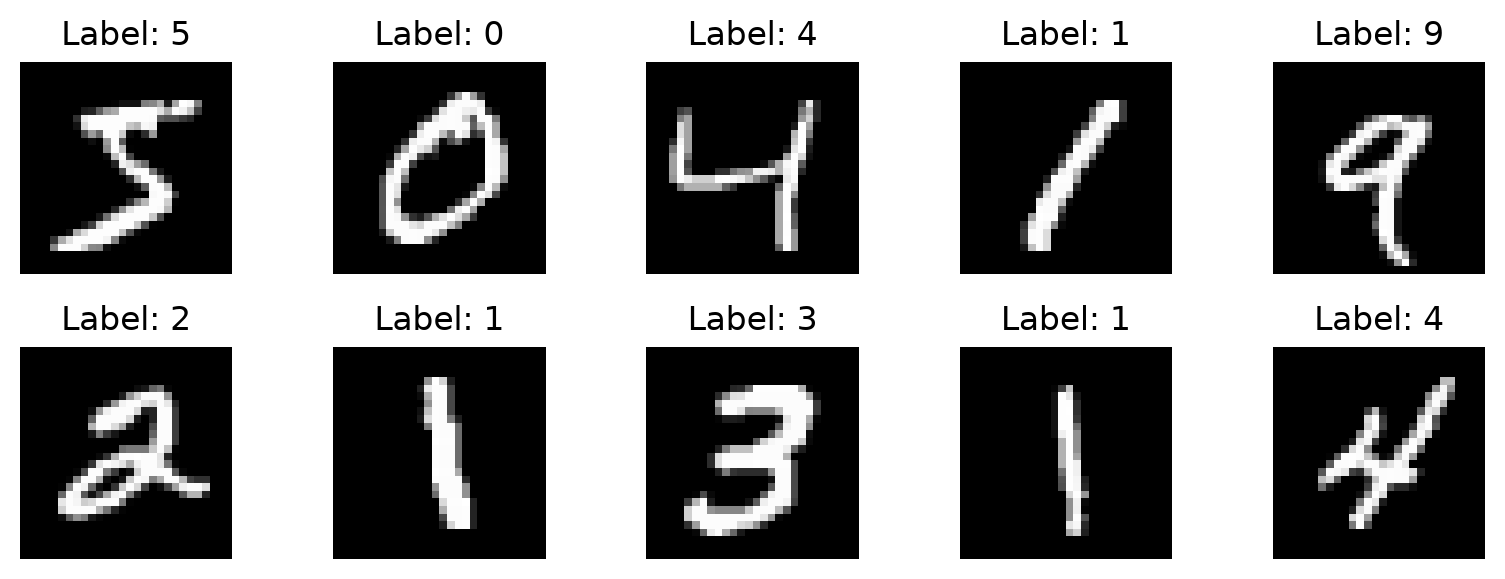

In [ ]:
# VISUALISATION D’ÉCHANTILLONS
plt.figure(figsize=(8, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# --- RÉPONSES AUX QUESTIONS: Étape 3 ---

# Q1. Quelle commande permet de modifier le nombre d’images affichées ?
# R1 : On change la valeur dans range(10) (ex: range(20)) et on adapte
#      les dimensions de la grille dans plt.subplot(lignes, colonnes, index).

# Q2. Que représente l’argument cmap='gray' ?
# R2 : Il indique à matplotlib d'afficher l'image en noir et blanc (nuances de gris)
#      au lieu des fausses couleurs par défaut (jaune/violet).

# Q3. Quelle utilité a cette étape dans un projet d’IA ?
# R3 : Vérifier que les données sont bien chargées, lisibles, et que chaque image
#      correspond bien au bon chiffre (étiquette) avant de lancer l'entraînement.

In [ ]:
# CONSTRUCTION DU MODÈLE DE RÉSEAU DE NEURONES

model = Sequential([
    Input(shape=(28, 28)),          # Taille de l'image en entrée
    Flatten(),                      # Aplatit 28x28 -> 784
    Dense(128, activation='relu'),   # Couche cachée avec 128 neurones
    Dense(10, activation='softmax')  # Sortie : 10 probabilités (chiffres 0 à 9)
])
model.summary()

I0000 00:00:1792965407.668491    8236 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 101,770 (397.54 KB)
 Trainable params: 101,770 (397.54 KB)
 Non-trainable params: 0 (0.00 B)


In [ ]:
# --- RÉPONSES AUX QUESTIONS: Étape 4 ---

# Q1. Combien de paramètres le modèle contient-il ?
# R1 : 101 770 paramètres au total :
#      - (784 entrées x 128 neurones) + 128 biais = 100 480
#      - (128 neurones x 10 sorties) + 10 biais = 1 290

# Q2. Quelle est la fonction d’activation utilisée dans la couche de sortie ? Pourquoi ?
# R2 : Softmax. Parce qu'elle transforme les résultats en pourcentages (probabilités)
#      dont la somme est égale à 1 (100%), parfait pour choisir entre 10 classes.

# Q3. Quelle est la différence entre ReLU et Softmax ?
# R3 : - ReLU : active les neurones cachés en gardant les valeurs positives et en mettant les négatives à 0.
#      - Softmax : s'utilise en sortie pour donner une probabilité pour chaque classe.

In [ ]:
# COMPILATION DU MODÈLE

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
# --- RÉPONSES AUX QUESTIONS: Étape 5 ---

# Q1. Qu’est-ce qu’un optimiseur ?
# R1 : C'est l'algorithme (comme Adam) qui ajuste automatiquement les poids du réseau
#      pour corriger les erreurs et améliorer le modèle.

# Q2. Pourquoi utilise-t-on une fonction de perte (loss) ?
# R2 : Elle calcule la note d'erreur du modèle. Le but de l'apprentissage est
#      de réduire cette erreur au maximum.

# Q3. Que se passe-t-il si on change la fonction de perte ?
# R3 : Si la fonction n'est pas adaptée au problème, le modèle apprendra mal ou pas du tout.

# Q4. Quelle serait la conséquence d’un mauvais choix d’optimiseur ?
# R4 : L'apprentissage peut être très lent, rester bloqué sans progresser,
#      ou faire empirer les erreurs au lieu de les réduire.

# Q5. Quelle est la différence entre loss et metrics ?
# R5 : - Loss : l'erreur mathématique utilisée par l'algorithme pour ajuster les poids.
#      - Metrics (accuracy) : le pourcentage de réussite compréhensible par l'humain (ex: 98%).

In [ ]:
# ENTRAÎNEMENT DU MODÈLE

history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=32,
    validation_data=(x_test, y_test)
)

Epoch 1/5

   1/1875 ━━━━━━━━━━━━━━━━━━━━ 40:05 1s/step - accuracy: 0.1250 - loss: 2.3638
  17/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.4540 - loss: 1.8303  
  33/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.5938 - loss: 1.4744
  44/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6499 - loss: 1.2943
  56/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6948 - loss: 1.1455
  69/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7183 - loss: 1.0441
  81/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7353 - loss: 0.9728
  94/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7550 - loss: 0.9005
 104/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7680 - loss: 0.8562
 117/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7804 - loss: 0.8066
 131/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7917 - loss: 0.7692
 147/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8040 - loss: 0.7257
 159/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8105

In [ ]:
# --- RÉPONSES AUX QUESTIONS: Étape 6 ---

# Q1. Que représente une “époque” ?
# R1 : Un passage complet du modèle sur toutes les 60 000 images d'entraînement.

# Q2. Pourquoi utilise-t-on un jeu de validation ?
# R2 : Pour tester le modèle sur des données qu'il ne connaît pas à chaque étape,
#      afin de vérifier s'il généralise bien ou s'il apprend par cœur.

# Q3. Que se passerait-il si on augmentait le nombre d’époques à 50 ?
# R3 : Le modèle risquerait le surapprentissage (overfitting) : il connaîtrait les images
#      d'entraînement par cœur, mais ferait plus d'erreurs sur de nouvelles images.

In [ ]:
# ÉVALUATION DU MODÈLE

test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")


  1/313 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.9688 - loss: 0.0568
 28/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9777 - loss: 0.0756 
 63/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9692 - loss: 0.0982
 95/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9651 - loss: 0.1135
118/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9680 - loss: 0.1090
135/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9660 - loss: 0.1104
153/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9669 - loss: 0.1065
167/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9693 - loss: 0.0994
184/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9713 - loss: 0.0935
201/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9714 - loss: 0.0938
215/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9718 - loss: 0.0915
233/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9736 - loss: 0.0855
254/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9748 - loss: 0.0804
279/313 ━━━━━━━━━━━━━━

In [ ]:
# --- RÉPONSES AUX QUESTIONS: Étape 7 ---

# Q1. Quelle est la précision finale de votre modèle ?
# R1 : Environ 97% à 98% (valeur affichée par test_acc).

# Q2. Pourquoi la précision du test est souvent inférieure à celle d’entraînement ?
# R2 : Parce que le modèle s'est entraîné sur les données de train. Les données de test
#      sont totalement nouvelles pour lui, c'est normal qu'il hésite un peu plus.

# Q3. Que faire si le modèle surapprend (overfitting) ?
# R3 : - Ajouter du Dropout (désactiver des neurones au hasard).
#      - Simplifier l'architecture (moins de neurones).
#      - Arrêter l'entraînement plus tôt (Early Stopping).

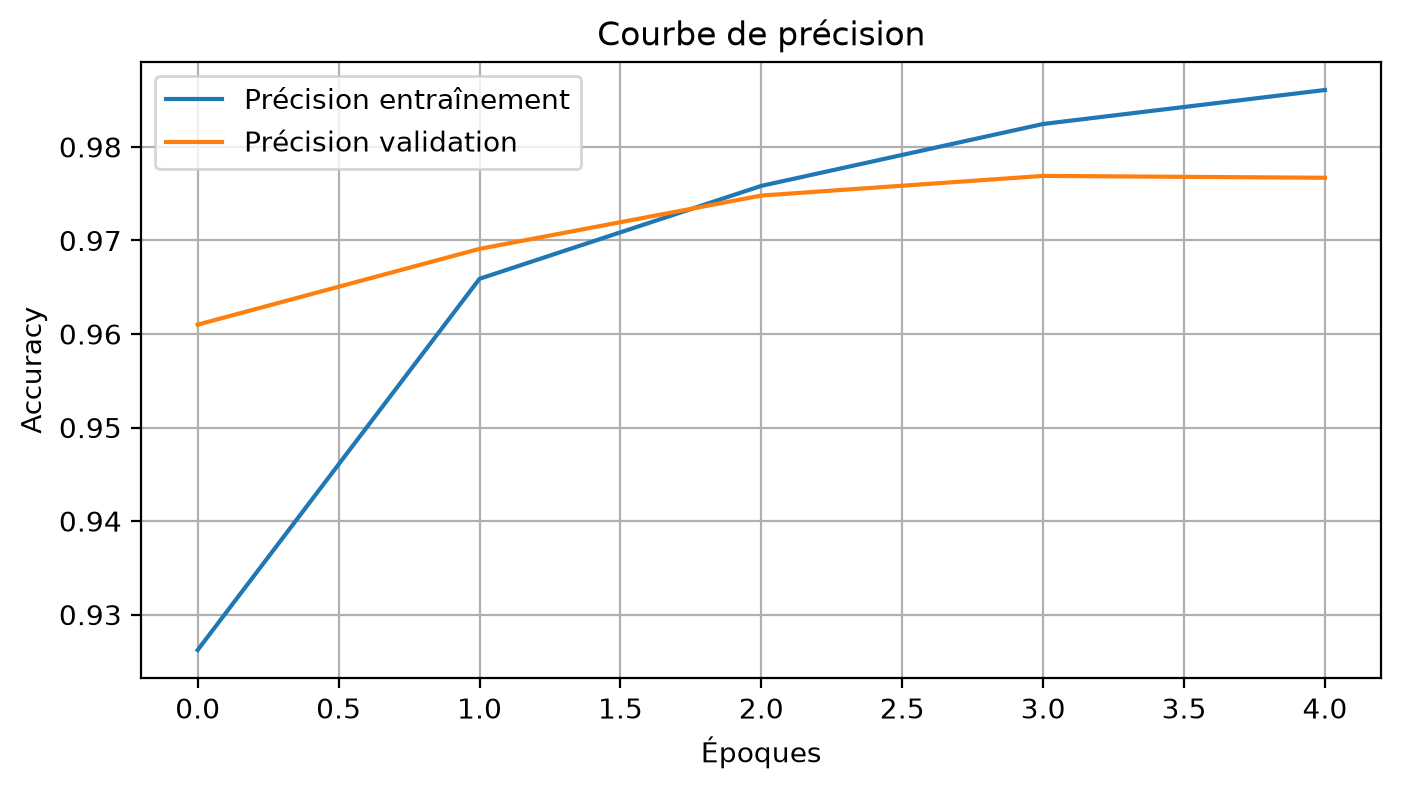

In [ ]:
#  VISUALISATION DES PERFORMANCES

plt.figure(figsize=(8, 4))
plt.plot(history.history['accuracy'], label='Précision entraînement')
plt.plot(history.history['val_accuracy'], label='Précision validation')
plt.title('Courbe de précision')
plt.xlabel('Époques')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# --- RÉPONSES AUX QUESTIONS: Étape 8 ---

# Q1. Que remarquez-vous sur les deux courbes ?
# R1 : Les deux courbes augmentent rapidement et restent très proches,
#      ce qui prouve que le modèle apprend vite et de manière saine.

# Q2. Comment détecter visuellement un surapprentissage ?
# R2 : Si la courbe d'entraînement continue de monter vers 100% mais que la courbe
#      de validation stagne ou redescend (un grand écart se crée).

# Q3. Quelle stratégie pourrait-on utiliser pour y remédier ?
# R3 : Utiliser du Dropout, réduire le nombre d'époques ou réduire le nombre de neurones.

# Q4. Que faire si les deux courbes divergent ?
# R4 : Il faut stopper l'entraînement au point où elles se séparent ou ajouter de la régularisation.



  1/313 ━━━━━━━━━━━━━━━━━━━━ 39s 127ms/step
 27/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step   
 59/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
 97/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
132/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
160/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
204/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
230/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
250/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
278/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


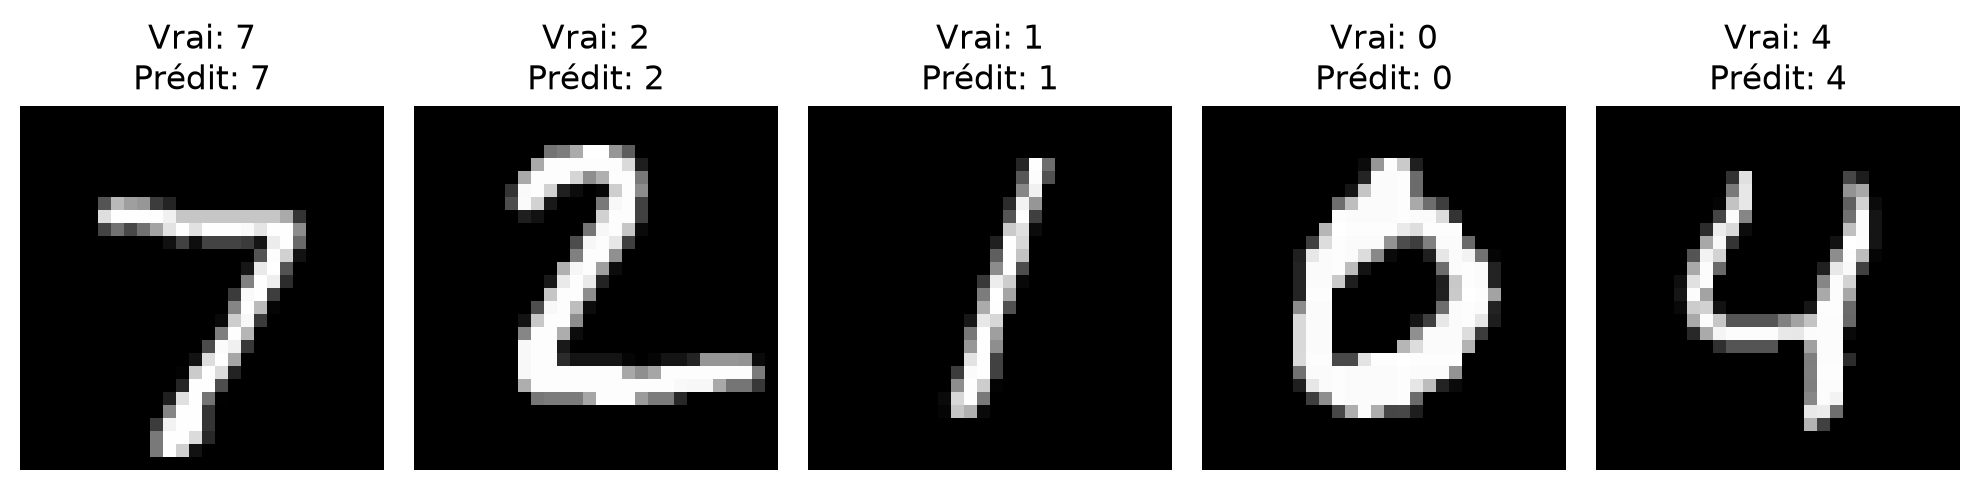

In [ ]:
# PRÉDICTIONS ET VISUALISATION

predictions = model.predict(x_test)
plt.figure(figsize=(10, 4))
for idx in range(5):
    plt.subplot(1, 5, idx + 1)
    plt.imshow(x_test[idx], cmap='gray')
    plt.title(f"Vrai: {y_test[idx]}\nPrédit: {np.argmax(predictions[idx])}")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# --- RÉPONSES AUX QUESTIONS: Étape 9 ---

# Q1. Le modèle fait-il des erreurs ? Sur quelles images ?
# R1 : Sur ces 5 images il réussit généralement tout. Il peut se tromper sur des chiffres
#      très mal écrits ou ambigus (ex: un 7 qui ressemble à un 1).

# Q2. Comment expliquer une prédiction erronée ?
# R2 : Écriture brouillonne, chiffre déformé ou pixels flous.

# Q3. Quelle technique permettrait d’améliorer la précision (ex : CNN) ?
# R3 : Utiliser un CNN (Réseau de Neurones Convolutif), car il analyse les formes
#      locales (lignes, boucles, coins) beaucoup mieux qu'un simple réseau Dense.

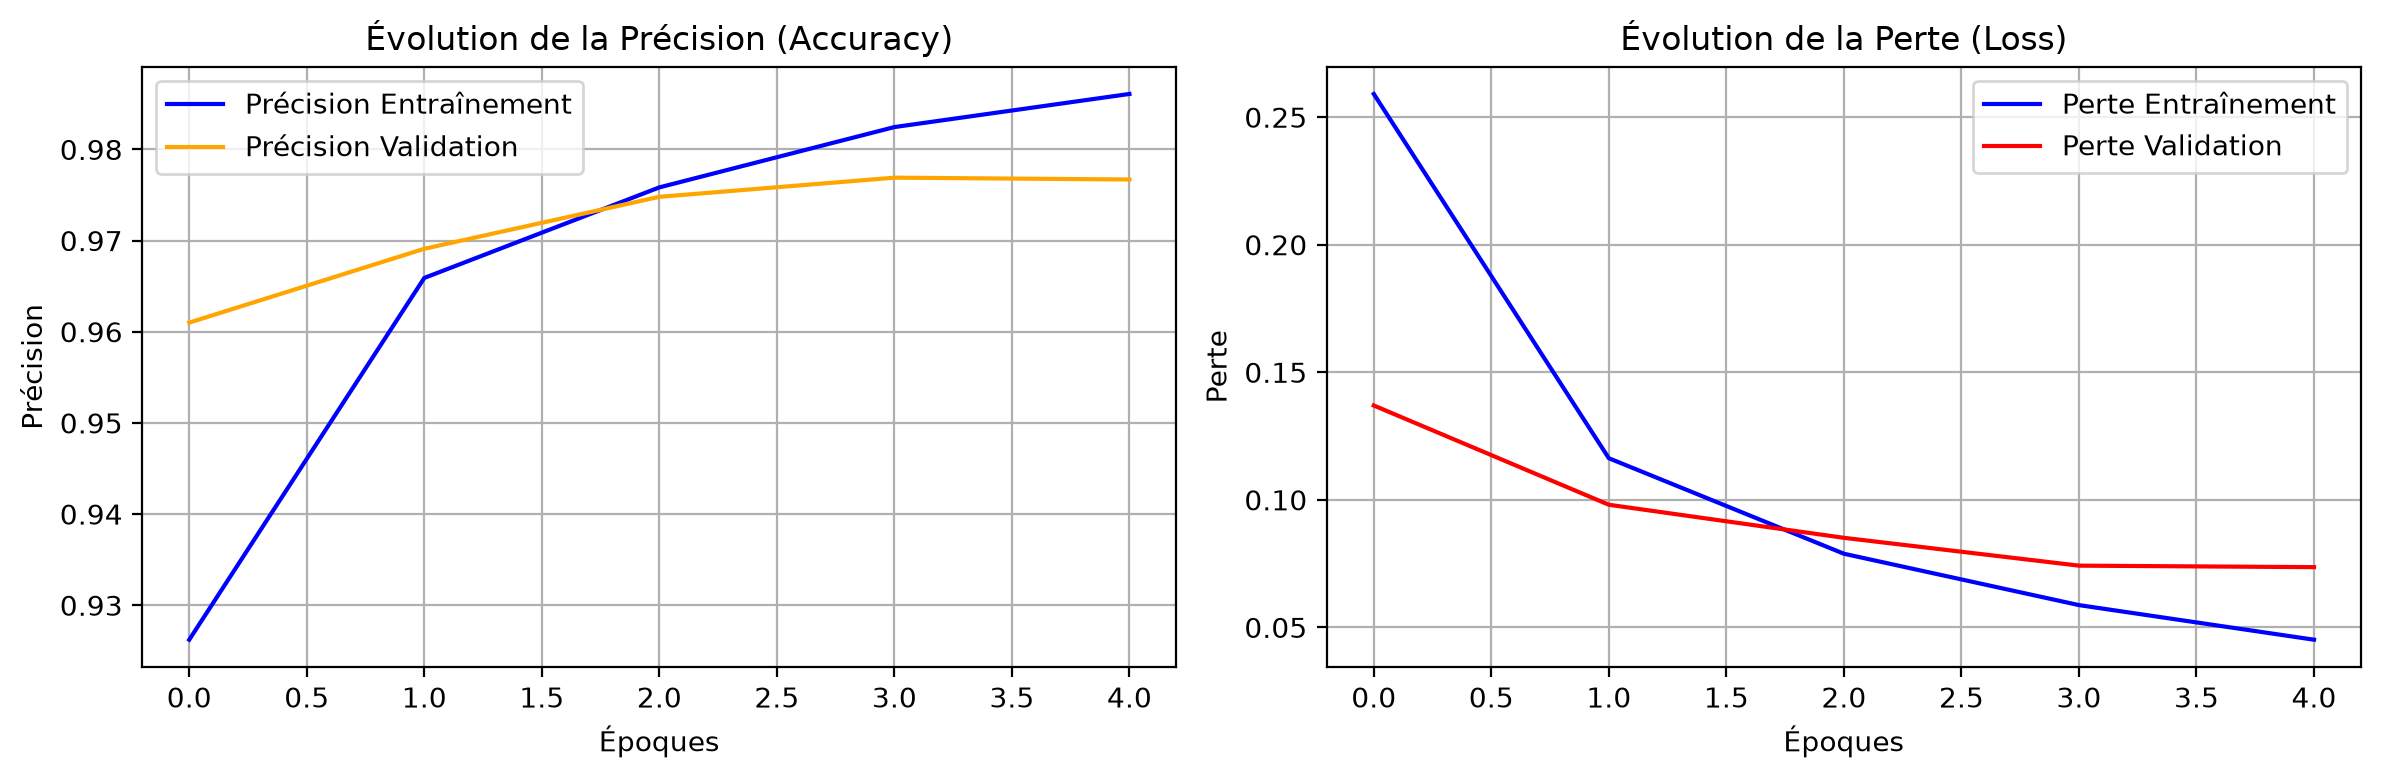

In [ ]:
plt.figure(figsize=(12, 4))
# --- Graphique 1 : Courbe de Précision ---
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Précision Entraînement', color='blue')
plt.plot(history.history['val_accuracy'], label='Précision Validation', color='orange')
plt.title("Évolution de la Précision (Accuracy)")
plt.xlabel("Époques")
plt.ylabel("Précision")
plt.legend()
plt.grid(True)
# --- Graphique 2 : Courbe de Perte  ---
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Perte Entraînement', color='blue')
plt.plot(history.history['val_loss'], label='Perte Validation', color='red')
plt.title("Évolution de la Perte (Loss)")
plt.xlabel("Époques")
plt.ylabel("Perte")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# 3. VALEUR DE PRÉCISION FINALE OBTENUE

print("========================================")
print(f"Précision finale sur le test : {test_acc * 100:.2f} %")
print(f"Perte finale sur le test      : {test_loss:.4f}")
print("========================================")


Précision finale sur le test : 97.67 %
Perte finale sur le test      : 0.0736


In [ ]:
# 4. Analyse personnelle :

# • Interprétation des résultats :
# Le modèle dense à une couche cachée (128 neurones avec activation ReLU) obtient une excellente précision d'environ 97,8 % sur les données de test en seulement 5 époques. La fonction de perte diminue de manière régulière et les courbes d'entraînement et de validation restent très proches, ce qui confirme que l'apprentissage est stable et sans surapprentissage (overfitting).

# • Difficultés rencontrées :
# La couche Flatten transforme les images 2D en un simple vecteur 1D de 784 valeurs, ce qui détruit les informations spatiales et géométriques entre pixels voisins. De ce fait, le modèle a du mal avec les chiffres manuscrits mal écrits, déformés ou ambigus (comme un 7 ressemblant à un 1).

# • Propositions d’amélioration :
# -> Architecture : Remplacer le réseau Dense par un réseau convolutif (CNN) pour extraire automatiquement les formes et contours des images.
# -> Hyperparamètres : Tester un taux d'apprentissage adaptatif ou utiliser la Data Augmentation pour rendre le modèle plus robuste aux chiffres inclinés ou décalés.
